# Reservoir subsidence: Van Opstal and Tempone

One notebook for the mathematics of surface subsidence from a prescribed, valid dataset.
Run from top to bottom. Dependencies: NumPy, SciPy, pandas and Matplotlib. No package imports,
test suite or input-validation code.

The main example compares **Van Opstal (1974)** with the **surface specialization of
Tempone, Fjær & Landrø (2010)** in the layout of their Figure 3. Both curves are calculated,
not traced from the paper. A second comparison uses independently fitted Poisson-dependent coefficients, following
TNO Appendix A. The last section applies the same functions to the repository's
synthetic reservoir CSV. All displacements below are **positive downward**; distances are metres.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss
from scipy.special import j0

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
from functools import lru_cache
from scipy.optimize import least_squares


## 1. Compaction and the Geertsma–Van Opstal kernel

For source cell $i$, define the positive depletion magnitude $p_d=p_{initial}-p_{final}$,
the compaction strength $D_i=A_i h_i C_{m,i}p_{d,i}$ [m³], and horizontal distance $r_i$.
Surface subsidence is $s(x,y)=\sum_i D_i G(r_i,c_i,k_i)$.
Here $c$ is source-centre depth and $k$ is basement depth from the same surface datum.

The Geertsma surface kernel is
$$G_G(r,c)=\frac{1-\nu}{\pi}\frac{c}{(r^2+c^2)^{3/2}}.$$
For the historical Figure 3 comparison we retain the original coefficients for
$\nu=0.25$: $(a_{11},a_{12},a_{21},a_{22},b_{11},b_{21})=(1,-0.778,2,2.8,-0.2,4)$.
The repeated $a$ terms are written as a two-term sum to keep the expression compact.

For other Poisson ratios, calculate coefficients independently using **TNO2022_R11962,
Appendix A.1** as the methodological reference. With $x=\lambda k$,
$$\Phi(x,\nu)=\frac{1}{2[(1-2\nu)^2+x^2+(3-4\nu)\cosh^2x]},$$
$$\widehat\Phi=a_{11}e^{-a_{21}x}+a_{12}e^{-a_{22}x}+b_{11}xe^{-b_{21}x}.$$
Following TNO's normalization, fix $a_{11}=1$. Exact matching at $x=0$ gives
$a_{12}=1/[8(1-\nu)^2]-1$. Fit the remaining four coefficients by minimizing
$\sum_j[\widehat\Phi(x_j)-\Phi(x_j)]^2$ on **1001 equally spaced points over [0,10]**,
with equal absolute-residual weights. Our starting values are $(2,2.8,-0.2,4)$;
bounds are $(1.01,1.01,-5,1.01)$ to $(10,20,5,40)$ in the order
$(a_{21},a_{22},b_{11},b_{21})$. Image exponents above one keep image sources below
all physical source centres $0<c<k$. Bounds and tolerances are numerical fitting
choices, not input validation.

These are our own numerical fits: no TNO coefficient table or tenth-degree polynomial
is used. Unlike TNO's final polynomial approximation, $a_{12}$ retains its exact
zero-wavenumber value. Fixing $a_{11}=1$ follows that approximation convention;
it does not impose exact large-$x$ asymptotics for every $\nu$. Coefficients are
cached once per distinct $\nu$. The demonstrations cover $0.1\leq\nu\leq0.4$;
accuracy outside the demonstrated geometry and parameter range is not established.


In [2]:
def spectral_phi(x, nu):
    return 1/(2*((1-2*nu)**2+x*x+(3-4*nu)*np.cosh(x)**2))

def phi_approx(x, coefficients):
    a11, a12, a21, a22, b11, b21 = coefficients
    return a11*np.exp(-a21*x)+a12*np.exp(-a22*x)+b11*x*np.exp(-b21*x)

@lru_cache(None)
def fit_coefficients(nu):
    x_fit = np.linspace(0, 10, 1001)
    a12 = 1/(8*(1-nu)**2)-1
    def residual(p):
        a21, a22, b11, b21 = p
        return phi_approx(x_fit, (1, a12, a21, a22, b11, b21))-spectral_phi(x_fit, nu)
    fit = least_squares(residual, [2, 2.8, -0.2, 4],
                        bounds=([1.01, 1.01, -5, 1.01], [10, 20, 5, 40]),
                        ftol=1e-13, xtol=1e-13, gtol=1e-13, max_nfev=3000)
    a21, a22, b11, b21 = fit.x
    return (1.0, a12, a21, a22, b11, b21)

original_coefficients = (1.0, -0.778, 2.0, 2.8, -0.2, 4.0)

def geertsma(r, c, nu=0.25):
    return (1-nu)/np.pi * c/(np.asarray(r)**2+c**2)**1.5

def van_opstal(r, c, k, nu=0.25, coefficients=None):
    a11, a12, a21, a22, b, b21 = (fit_coefficients(nu) if coefficients is None
                                  else coefficients)
    r2 = np.asarray(r)**2
    q = 3-4*nu
    correction = np.zeros_like(r2, dtype=float)
    for a, image_depth in [(a11, a21), (a12, a22)]:
        u, v = image_depth*k-c, image_depth*k+c
        n1, n2 = r2+u**2, r2+v**2
        n3, n4 = r2+(v+2*k)**2, r2+(u+2*k)**2
        correction += a*((u-2*k)/n1**1.5 + (2*k-q*q*v)/n2**1.5
                         - q*(v+2*k)/n3**1.5 + q*(u+2*k)/n4**1.5
                         + 6*k*u*u/n1**2.5 + 6*k*v*(6*k-v)/n2**2.5
                         - 60*k*k*v**3/n2**3.5)
    u, v = b21*k-c, b21*k+c
    n1, n2 = r2+u*u, r2+v*v
    n3, n4 = r2+(u+2*k)**2, r2+(v+2*k)**2
    correction += (-b*k/n1**1.5 + q*q*b*k/n2**1.5
                   - q*b*k/n3**1.5 + q*b*k/n4**1.5
                   - 3*b*k*u*(6*k-u)/n1**2.5
                   + (3*b*k*v*(6*k-q*q*v)-36*b*k**3)/n2**2.5
                   + 3*q*b*k*(u+2*k)**2/n3**2.5
                   - 3*q*b*k*(v+2*k)**2/n4**2.5
                   + 30*b*k*k*u**3/n1**3.5
                   + 30*b*k*k*v*v*(12*k-v)/n2**3.5
                   - 420*b*k**3*v**4/n2**4.5)
    return geertsma(r, c, nu)+(1-nu)/(2*np.pi)*correction


## 2. Tempone's rigid-basement surface solution

Implement Eqs. (26), (29)–(32), (33) and (34), with observation depth $z=0$.
In the paper's potential convention use the signed pressure change $\Delta p=-p_d$,
so $A_g(1+\nu)/E=-D/(4\pi)$. This yields positive-downward subsidence.
At the basement, $k>c$ and $\epsilon=-1$. Define $t=\lambda k$ and

$$\begin{aligned}
\ell &= (4\nu-3+2t)e^{-\lambda(k+c)}-e^{-\lambda(k-c)},\\
m &= (4\nu-3-2t)e^{-\lambda(k+c)}+e^{-\lambda(k-c)},\\
\Delta &= (4\nu-3)\cosh^2t-t^2-(1-2\nu)^2,\\
\widehat C=\frac{C}{A_g}
&=\frac{\lambda}{\Delta}\{\ell[(1-2\nu)\sinh t-t\cosh t]
+m[2(1-\nu)\cosh t+t\sinh t]\}.
\end{aligned}$$

The $B$ term in Eq. (26) vanishes at $z=0$, leaving
$$G_T(r,c,k)=G_G(r,c)-\frac{1-\nu}{2\pi}
\int_0^\infty\widehat C(\lambda;c,k,\nu)J_0(\lambda r)\,d\lambda.$$

This is a separate Bessel-integral calculation, not the Van Opstal image approximation.
For the examples here, evaluate the integral with 240 Gauss–Legendre nodes over
$0<\lambda k<40$. These numerical settings are fixed for this notebook's datasets;
the upper integration bound is an approximation to infinity.


In [3]:
nodes, weights = leggauss(240)

def tempone(r, c, k, nu=0.25):
    lam, w = (nodes+1)*20/k, weights*20/k
    t = lam*k
    sh, ch = np.sinh(t), np.cosh(t)
    L = (4*nu-3+2*t)*np.exp(-lam*(k+c))-np.exp(-lam*(k-c))
    M = (4*nu-3-2*t)*np.exp(-lam*(k+c))+np.exp(-lam*(k-c))
    delta = (4*nu-3)*ch**2-t**2-(1-2*nu)**2
    C_hat = lam/delta*(L*((1-2*nu)*sh-t*ch)+M*(2*(1-nu)*ch+t*sh))
    correction = j0(np.asarray(r)[..., None]*lam) @ (w*C_hat)
    return geertsma(r, c, nu)-(1-nu)/(2*np.pi)*correction

def subsidence(x, y, sources, kernel, nu=0.25):
    s = np.zeros(np.broadcast(x, y).shape)
    for row in sources.itertuples(index=False):
        r = np.hypot(x-row.x_m, y-row.y_m)
        s += row.D_m3*kernel(r, row.c_m, row.k_m, nu)
    return s


## 3. Figure 3 comparison: a compacting cylinder

Section 5 of Tempone et al. gives radius **500 m**, thickness **100 m**, reservoir
depth **800 m**, basement **150 m beneath the reservoir bottom**,
depletion **10 MPa**, $C_m=2.5\times10^{-4}$ MPa⁻¹, and $\nu=0.25$.

The paper uses 715 full-thickness nuclei of base area 1100 m² but does not list
their coordinates. Here 13 equal-area annuli × 55 angular sectors give **715 nuclei**
at centre depth 750 m; each area is $\pi R^2/715=1098.459$ m², preserving the exact disk area.
Radial midpoints are taken in $r^2$. This is a documented discretization of the stated
geometry, not a claim to recover the authors' source-cell layout. The depth of 800 m is interpreted as the reservoir bottom; the centre is therefore
750 m, the top is 700 m, and the basement is 950 m. This interpretation reproduces the approximately 95 mm
centre displacement visible in Figure 3. Both models use
exactly the same source table and compaction strengths.


In [4]:
R, h = 500.0, 100.0
z_bottom, basement_gap = 800.0, 150.0
c = z_bottom-h/2  # source-centre depth: 750 m
k = z_bottom+basement_gap  # basement depth: 950 m
cm, depletion, nu = 2.5e-4, 10.0, 0.25  # 1/MPa, MPa, dimensionless
rho = R*np.sqrt((np.arange(13)+0.5)/13)
theta = 2*np.pi*np.arange(55)/55
sources = pd.DataFrame({
    'x_m': (rho[:, None]*np.cos(theta)).ravel(),
    'y_m': (rho[:, None]*np.sin(theta)).ravel(),
    'c_m': c, 'k_m': k, 'D_m3': np.pi*R**2/715*h*cm*depletion,
})
x = np.linspace(0, 2000, 201)
legacy_kernel = lambda r, c, k, nu: van_opstal(r, c, k, nu, original_coefficients)
s_vo = subsidence(x, 0.0, sources, legacy_kernel, nu)
s_t = subsidence(x, 0.0, sources, tempone, nu)
print(f'Compaction strength: {sources.D_m3.sum():,.1f} m³')
print(f'Centre: Van Opstal = {1000*s_vo[0]:.3f} mm; Tempone = {1000*s_t[0]:.3f} mm')
print(f'Maximum absolute profile difference = {1000*np.max(np.abs(s_t-s_vo)):.3f} mm')
print(f'Difference / Tempone peak = {100*np.max(np.abs(s_t-s_vo))/s_t.max():.3f}%')


Compaction strength: 196,349.5 m³
Centre: Van Opstal = 94.830 mm; Tempone = 95.101 mm
Maximum absolute profile difference = 0.271 mm
Difference / Tempone peak = 0.284%


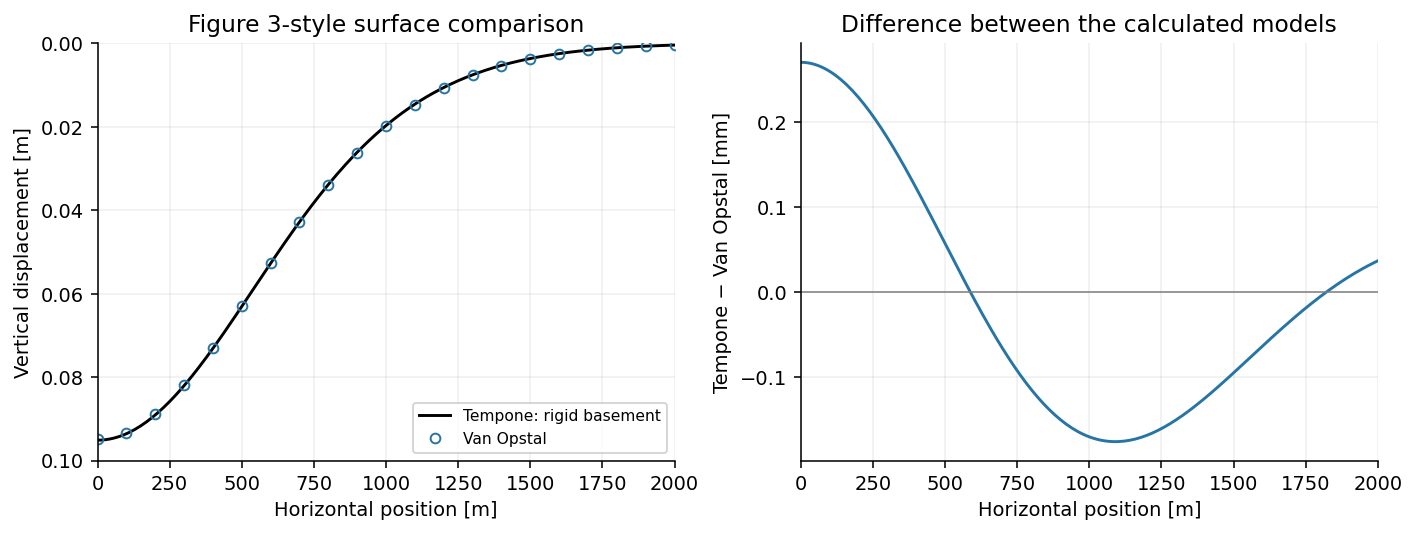

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.7), layout='constrained')
ax[0].plot(x, s_t, color='black', label='Tempone: rigid basement')
ax[0].plot(x[::10], s_vo[::10], 'o', mfc='none', mec='#2675a5', ms=5,
           label='Van Opstal')
ax[0].set(xlabel='Horizontal position [m]', ylabel='Vertical displacement [m]',
          xlim=(0, 2000), ylim=(0.10, 0), title='Figure 3-style surface comparison')
ax[0].legend(fontsize=8, loc='lower right')
ax[1].plot(x, 1000*(s_t-s_vo), color='#2675a5')
ax[1].axhline(0, color='gray', lw=0.8)
ax[1].set(xlabel='Horizontal position [m]', ylabel='Tempone − Van Opstal [mm]',
          xlim=(0, 2000), title='Difference between the calculated models')
plt.show()


**Interpretation.** With 800 m interpreted as the reservoir bottom, the calculated
centre subsidence is **95.101 mm (Tempone)** and **94.830 mm (Van Opstal)**.
The maximum difference over the profile is **0.271 mm**, or **0.284%** of the
Tempone peak. This agrees visually with the approximately **0.095 m** centre
displacement in Figure 3 and resolves the earlier approximately 88 mm result,
which used 800 m as the centre and 1000 m as the basement.

The 715-nucleus coordinates are our documented discretization, not the authors'
original coordinates. The comparison is consistent with the published figure;
it is not a point-by-point comparison against published numerical data.
Neither curve is tuned or rescaled. The markers above are calculated Van Opstal values.


## 4. Independently fitted coefficients and comparison with Tempone

The table reports our calculated coefficients, not TNO's tabulated values. The curves
use the same cylinder geometry and compaction strength as Section 3, varying only
$\nu$ in the displacement kernels: $C_m$ is held fixed to isolate this effect.
Changing $\nu$ at fixed Young's modulus would also change the elastic $C_m$.

The second table compares **point-source kernels** over $0\leq r/k\leq4$ at four
source-depth ratios $c/k$. This prevents a good fit to one integrated reservoir bowl
from hiding errors at other depths. Errors are maximum absolute differences divided
by the maximum absolute Tempone response on the profile, not pointwise relative
errors near zero. These are mathematical comparison calculations within the notebook.


      a11       a12       a21       a22       b11        b21
nu                                                          
0.10  1.0 -0.845679  2.034509  2.564951 -0.139005   4.344766
0.20  1.0 -0.804688  1.995846  2.600306 -0.105575   5.919446
0.25  1.0 -0.777778  1.979378  2.653816 -0.099569   7.370443
0.30  1.0 -0.744898  1.963648  2.739482 -0.100870   9.522657
0.35  1.0 -0.704142  1.945948  2.866936 -0.108397  12.543273
0.40  1.0 -0.652778  1.922174  3.055099 -0.121415  16.453484

Cylinder profiles:
  nu  max_error_mm  peak_normalized_error_pct
0.10        0.2076                     0.2034
0.25        0.2185                     0.2298
0.35        0.8107                     0.8913
0.40        1.5240                     1.7090

Point-source maximum errors / Tempone peak [%]:
c/k     0.30    0.60    0.80    0.95
nu                                  
0.10  0.0014  0.0923  0.2950  0.5191
0.20  0.0054  0.2244  0.7854  1.5782
0.25  0.0078  0.1768  0.6731  1.4604
0.30  0.0112  0.1102  0.3306

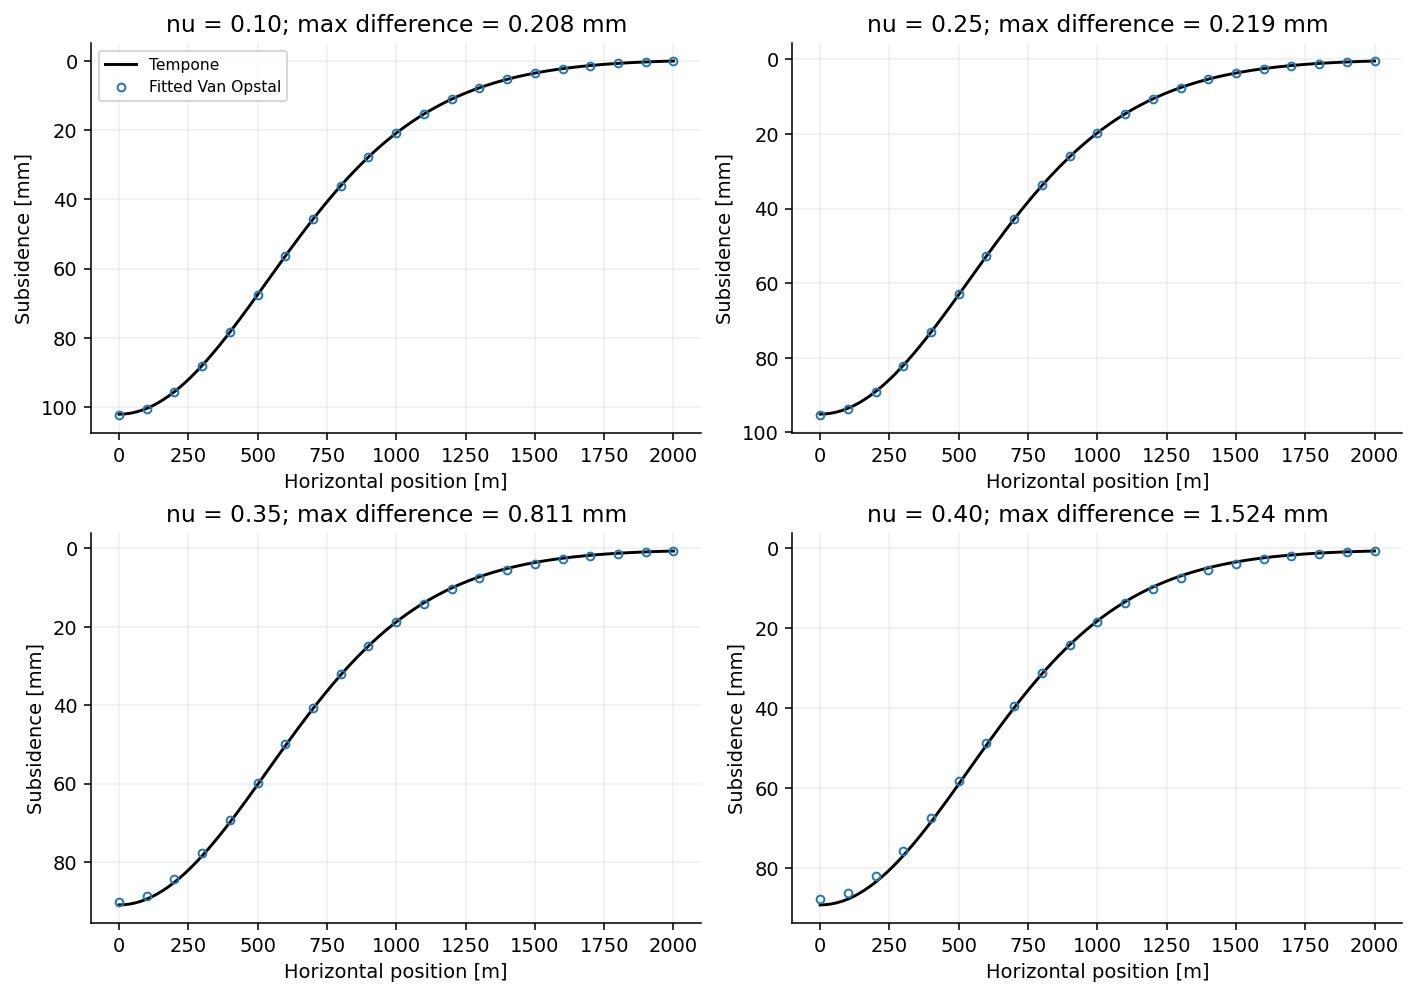

In [6]:
nu_values = [0.10, 0.20, 0.25, 0.30, 0.35, 0.40]
coefficient_table = pd.DataFrame([fit_coefficients(v) for v in nu_values],
                               index=nu_values, columns=['a11', 'a12', 'a21', 'a22', 'b11', 'b21'])
coefficient_table.index.name = 'nu'
print(coefficient_table.round(6).to_string())

fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout='constrained')
bowl_results = []
x_compare = np.linspace(0, 2000, 101)
for ax, v in zip(axes.flat, [0.10, 0.25, 0.35, 0.40]):
    fitted = subsidence(x_compare, 0.0, sources, van_opstal, v)
    reference = subsidence(x_compare, 0.0, sources, tempone, v)
    error_mm = 1000*np.max(np.abs(fitted-reference))
    error_pct = 100*np.max(np.abs(fitted-reference))/np.max(np.abs(reference))
    bowl_results.append([v, error_mm, error_pct])
    ax.plot(x_compare, reference*1000, color='black', label='Tempone')
    ax.plot(x_compare[::5], fitted[::5]*1000, 'o', mfc='none', ms=4, label='Fitted Van Opstal')
    ax.set(xlabel='Horizontal position [m]', ylabel='Subsidence [mm]',
           title=f'nu = {v:.2f}; max difference = {error_mm:.3f} mm')
    ax.invert_yaxis()
axes[0, 0].legend(fontsize=8)
plt.show()
print('\nCylinder profiles:')
print(pd.DataFrame(bowl_results, columns=['nu', 'max_error_mm', 'peak_normalized_error_pct']).round(4).to_string(index=False))

r_scaled = np.linspace(0, 4, 401)
kernel_errors = []
for v in nu_values:
    for depth_ratio in [0.30, 0.60, 0.80, 0.95]:
        reference = tempone(r_scaled, depth_ratio, 1.0, v)
        fitted = van_opstal(r_scaled, depth_ratio, 1.0, v)
        kernel_errors.append([v, depth_ratio,
                              100*np.max(np.abs(fitted-reference))/np.max(np.abs(reference))])
errors = pd.DataFrame(kernel_errors, columns=['nu', 'c/k', 'error_pct'])
print('\nPoint-source maximum errors / Tempone peak [%]:')
print(errors.pivot(index='nu', columns='c/k', values='error_pct').round(4).to_string())


**Approximation accuracy.** For the four cylinder profiles, maximum differences are
0.208–1.524 mm (0.203–1.709% of the respective Tempone peak). Across the displayed
point-source geometries the largest peak-normalized difference is 1.911%, at
$\nu=0.40$, $c/k=0.95$. The spectral least-squares objective does not directly minimize
spatial displacement error. These results characterize this compact approximation;
they are not a universal error bound. Tempone remains the reference when the observed
approximation error matters. The original Figure 3 comparison above deliberately keeps
the historical fixed coefficients, while the following dataset calculation uses the new fits.


## 5. Apply the same mathematics to a given reservoir table

This optional section reads the repository's unchanged synthetic dataset. Its $C_m$ and
depletion columns use **1/bar and bar**. It retains the dataset's per-reservoir basement
factors: summing these different-basement kernels is an illustrative approximation, not
a solution for one common horizontal basement. For a common basement, replace `k_m`
with a single prescribed depth. The preceding sections are self-contained. The Van Opstal calculation now uses our fitted
coefficients at the prescribed `dataset_nu`. Source-cell and field contributions still add linearly.


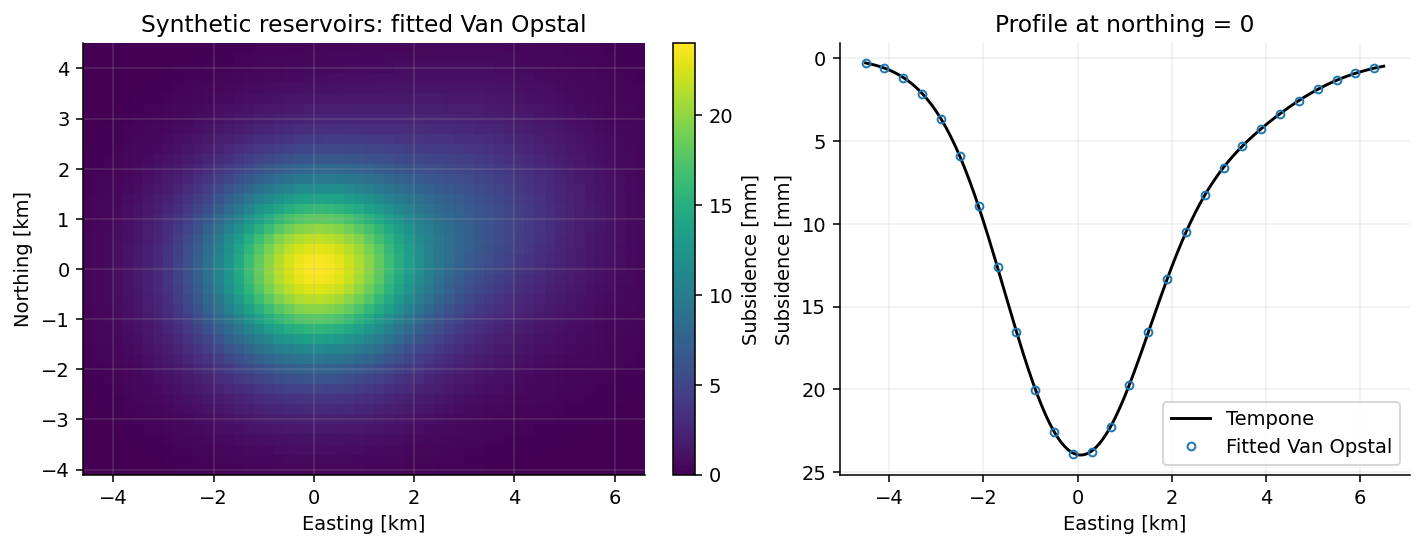

In [7]:
dataset_nu = 0.25
data = pd.read_csv('data/synthetic_reservoir.csv')
data['c_m'] = data.reservoir_depth_m
data['k_m'] = data.c_m*data.basement_depth_factor
data['D_m3'] = (data.source_cell_area_m2*data.thickness_m
                *data.compaction_coefficient_per_bar*data.pressure_depletion_bar)
gx, gy = np.arange(-4500, 6501, 200), np.arange(-4000, 4501, 200)
xx, yy = np.meshgrid(gx, gy)
surface = subsidence(xx, yy, data, van_opstal, dataset_nu)
profile_x = np.linspace(-4500, 6500, 221)
profile_vo = subsidence(profile_x, 0.0, data, van_opstal, dataset_nu)
profile_t = subsidence(profile_x, 0.0, data, tempone, dataset_nu)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
m = ax[0].pcolormesh(xx/1000, yy/1000, surface*1000, shading='auto', cmap='viridis')
fig.colorbar(m, ax=ax[0], label='Subsidence [mm]')
ax[0].set(xlabel='Easting [km]', ylabel='Northing [km]',
          title='Synthetic reservoirs: fitted Van Opstal', aspect='equal')
ax[1].plot(profile_x/1000, profile_t*1000, color='black', label='Tempone')
ax[1].plot(profile_x[::8]/1000, profile_vo[::8]*1000, 'o', mfc='none', ms=4,
           label='Fitted Van Opstal')
ax[1].set(xlabel='Easting [km]', ylabel='Subsidence [mm]', title='Profile at northing = 0')
ax[1].invert_yaxis()
ax[1].legend()
plt.show()


## References

- Tempone, P., Fjær, E. & Landrø, M. (2010). *Improved solution of displacements due to
  a compacting reservoir over a rigid basement*. Applied Mathematical Modelling 34,
  3352–3362. [doi:10.1016/j.apm.2010.02.025](https://doi.org/10.1016/j.apm.2010.02.025).
  Surface specialization: Eqs. (26), (29)–(34); example: Section 5 and Figure 3.
- Van Opstal, G.H.C. (1974). *The effect of base-rock rigidity on subsidence due to
  reservoir compaction*. Proceedings of the Third Congress of the ISRM, 1102–1111.
- Geertsma, J. (1973). *A basic theory of subsidence due to reservoir compaction:
  the homogeneous case*. Verhandelingen KNGMG 28, 43–62.

Van Opstal implementation and synthetic data adapted from this repository at
[`ec202514`](https://github.com/asengel/subsidence-model/tree/ec202514c3f76f62e044069ef16c5aa90ed099b6).

- TNO (2023). *The PySub Subsidence Model Framework: Technical Reference*,
  TNO2022_R11962, 14 March 2023, Appendix A.1–A.2.
  [Report and download](https://www.kemprogramma.nl/documenten/2023/03/15/kem-16a-rapport-the-pysub-modeling-framework-tno2022_r11962-14032023-public).
  Reference for the spectral approximation and least-squares approach; coefficient
  values in this notebook are independently calculated.
